# AI Methods I Hackathon - GROUP 6
## Finding Similar Floor Plans with Autoencoders

Team members: LUCA OBEJDEANU, JEFF EL KHOURY, CHLOE HRAIBEH

### Our project

Architects often search through many floor plans to find useful design references. Our project explores whether an autoencoder can help retrieve visually similar plans.

We use CubiCasa5K floor-plan images to train a convolutional autoencoder. The encoder converts each plan into a short numerical representation, called a latent code.

For a new floor plan, we compare its code with the codes of stored plans and return the five closest matches.

### Our research question

Can an autoencoder learn a representation that helps us find visually similar floor plans?

### Our objectives

1. Prepare floor-plan images for training.
2. Train and compare at least three model setups.
3. Inspect the reconstructed images.
4. Use the latent codes for similarity search.
5. Save the selected model and reference codes for a future app.

### What is an autoencoder?

An autoencoder has two main parts:

- The encoder compresses an image into a smaller numerical code.
- The decoder tries to reconstruct the image from that code.

The model learns by reducing the difference between the input image and its reconstruction.

### Notebook organisation and saved outputs

The sections below follow the execution order from setup to model export.
Saved outputs are retained from the uploaded notebook. Reorganisation was checked
statically; the dataset and trained model files were not available in the editing
environment, so the full experiment was not rerun here. Recorded numerical findings
refer to the saved run and may differ after retraining.

Run the notebook from its project folder, with `data/cubicasa5k/` present. The optional
installation cell is commented out because the packages were already installed in
the recorded run. Uncomment it only when setting up a new environment.

### Contents

0. Setup
1. The data
2. Choosing our model
3. Convolutional autoencoder and first training run
4. Comparing latent sizes and diagnosing failed training
5. Latent space and similarity search
6. Final reconstruction evaluation
7. Saving the model and verifying ONNX
8. Day 1 deliverables
9. Conclusions and next steps

Appendix: possible extensions outside the current experiment

# 0. Setup

We use PyTorch to build and train the autoencoder.

The other libraries help us load images, organise results, produce figures and compare numerical representations.

We create folders for:

- data: the downloaded floor-plan dataset;
- figures: charts and image comparisons;
- results: experiment tables and retrieval results;
- models: saved model weights;
- model_app: files needed for the future application.

We set a random seed to make our experiments easier to reproduce.

Training uses a GPU when available and otherwise uses the CPU. Training time depends on the hardware, number of images and model settings.

In [1]:
# Optional: uncomment only when setting up a new environment.
# %pip install torch scikit-learn matplotlib onnx onnxscript onnxruntime pandas numpy pillow

In [2]:
import copy
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [3]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
RESULT_DIR = Path("results")
MODEL_DIR = Path("models")
MODEL_APP_DIR = Path("model_app")

for folder in [DATA_DIR, FIG_DIR, RESULT_DIR, MODEL_DIR, MODEL_APP_DIR]:
    folder.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.15.0+cpu, using device: cpu


# 1. The data

### Why floor plans?

Floor plans communicate the organisation of architectural spaces. Searching for relevant examples can support early design exploration.

We selected CubiCasa5K because it contains a collection of floor-plan images suitable for testing image reconstruction and similarity search.

### Dataset card

| Item | Description |
|---|---|
| Name | CubiCasa5K |
| Authors | Kalervo et al., 2019 |
| Source | https://zenodo.org/records/2613548 |
| Content | 5,000 floor-plan samples with detailed annotations |
| Provided split | 4,200 training, 400 validation and 400 test samples |
| Input used | Floor-plan images |
| Prepared image size | 128 × 128 pixels |
| Channels | One grayscale channel |
| Pixel range | 0–1 |
| Actual samples used | Training: 4,200; validation: 400; test: 400 |
| Licence | Publisher repository: CC BY-NC 4.0; retain and check the licence accompanying the downloaded archive |

### Image preparation

Each image is converted to grayscale, resized while preserving its proportions, and padded with white space to produce a 128 × 128 image.

Pixel values are divided by 255 to produce values between 0 and 1.

The resulting tensor has the shape:

(number of images, 1, 128, 128)

### Do we need the annotations?

The autoencoder learns to reconstruct the images, so category labels and SVG annotations are not required for this first version.

We retain each image's path or ID so that retrieved codes can be connected to the correct floor plans.

### Data splitting

We preserve the provided training, validation and test splits.

Training data are used to learn model weights. Validation data are used to compare setups. Test data are reserved for final evaluation.

### 1.1 Prepare each image

In [4]:
from PIL import Image, ImageOps
import numpy as np
import torch

def prepare_plan(path):
    with Image.open(path) as image:
        image = image.convert("L")

        image = ImageOps.pad(
            image,
            size=(128, 128),
            method=Image.Resampling.LANCZOS,
            color=255
        )

        array = np.asarray(image, dtype=np.float32) / 255.0

    return torch.from_numpy(array).unsqueeze(0)


### 1.2 Read the official split lists

In [5]:
from pathlib import Path

CUBI_DIR = Path("data") / "cubicasa5k"

def get_image_paths(split_file):
    split_path = CUBI_DIR / split_file

    folders = [
        line.strip().replace("\\", "/").lstrip("/")
        for line in split_path.read_text().splitlines()
        if line.strip()
    ]

    paths = [
        CUBI_DIR / folder / "F1_scaled.png"
        for folder in folders
    ]

    missing = [path for path in paths if not path.exists()]

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} images missing. First: {missing[0]}"
        )

    return paths

train_paths = get_image_paths("train.txt")
val_paths = get_image_paths("val.txt")
test_paths = get_image_paths("test.txt")

print("Training plans:", len(train_paths))
print("Validation plans:", len(val_paths))
print("Test plans:", len(test_paths))
print("Example image:", train_paths[0])

Training plans: 4200
Validation plans: 400
Test plans: 400
Example image: data\cubicasa5k\high_quality_architectural\6044\F1_scaled.png


### 1.3 Load the training validation and test tensors

In [6]:
def load_plans(paths, split_name):
    images = []

    for i, path in enumerate(paths):
        images.append(prepare_plan(path))

        if (i + 1) % 500 == 0 or i + 1 == len(paths):
            print(f"{split_name}: {i + 1}/{len(paths)} loaded")

    return torch.stack(images)

X_train = load_plans(train_paths, "Training")
X_val = load_plans(val_paths, "Validation")
X_test = load_plans(test_paths, "Test")

print("\nTensor shapes:")
print("Training:", tuple(X_train.shape))
print("Validation:", tuple(X_val.shape))
print("Test:", tuple(X_test.shape))

print("\nTraining pixel range:")
print(X_train.min().item(), "to", X_train.max().item())

Training: 500/4200 loaded
Training: 1000/4200 loaded
Training: 1500/4200 loaded
Training: 2000/4200 loaded
Training: 2500/4200 loaded


c:\Users\Chloe\hackathon group 6\.venv\Lib\site-packages\PIL\Image.py:3593: DecompressionBombWarning: Image size (90344064 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Training: 3000/4200 loaded
Training: 3500/4200 loaded
Training: 4000/4200 loaded
Training: 4200/4200 loaded
Validation: 400/400 loaded
Test: 400/400 loaded

Tensor shapes:
Training: (4200, 1, 128, 128)
Validation: (400, 1, 128, 128)
Test: (400, 1, 128, 128)

Training pixel range:
0.0 to 1.0


### 1.4 Inspect sample floor plans

Figure saved to figures\cubicasa_sample_plans.png


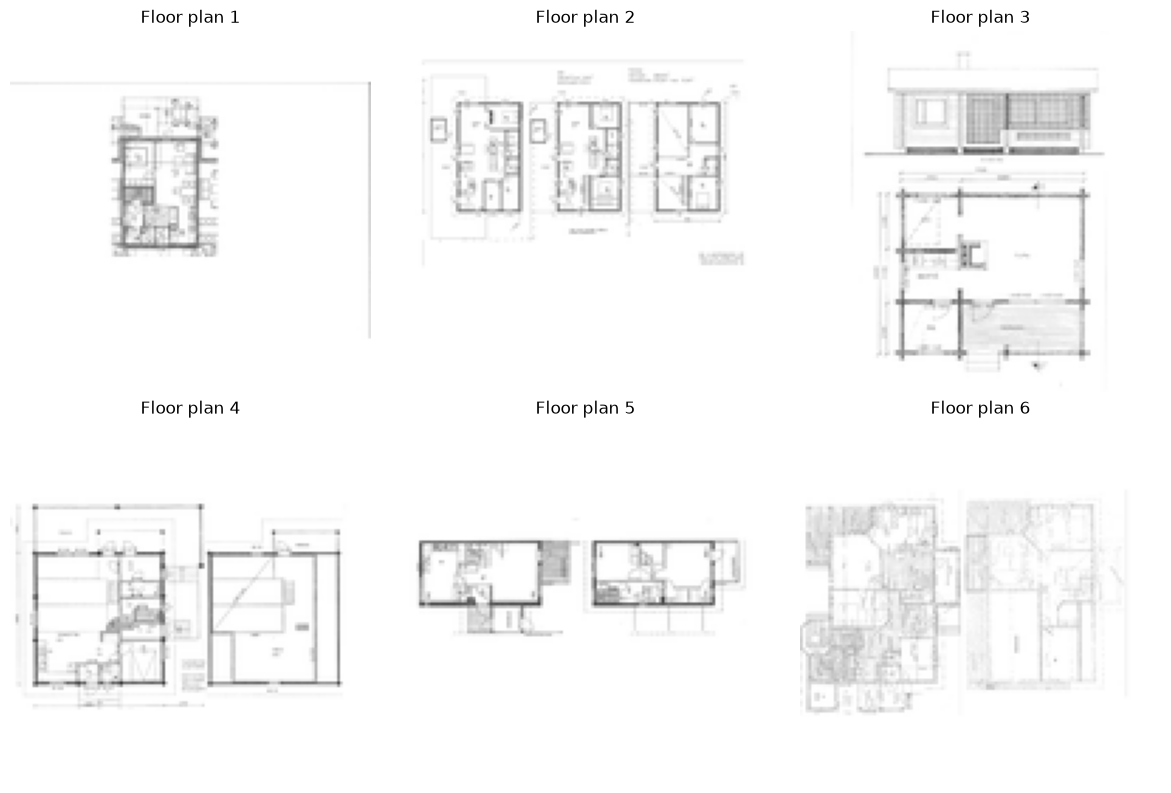

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Floor plan {i + 1}")
    ax.axis("off")

plt.tight_layout()
save_fig("cubicasa_sample_plans")
plt.show()

# 2. Choosing our model

We choose a convolutional autoencoder because our inputs are images.

Convolutional layers process local patterns using shared filters. This makes them suitable for learning visual features from floor-plan drawings.

Our main comparison changes the latent size while keeping the convolutional architecture and training conditions consistent.

The initial comparison uses these latent sizes:

- 8 values;
- 16 values;
- 32 values.

We compare reconstruction quality and model size, then inspect similarity retrieval with the selected model. A separate learning-rate retry is recorded as a troubleshooting experiment.

# 3. Convolutional autoencoder and first training run

### Encoder

The encoder receives a grayscale floor plan of 128 × 128 pixels.

Convolutional layers gradually reduce its spatial dimensions. The resulting features are compressed into a latent code.

For our architecture, the image dimensions decrease as follows:

128 → 64 → 32 → 16 → 8

### Latent code

The latent code is a short list of numbers learned from the image.

Its values are not predefined architectural measurements. We test whether distances between these codes correspond to useful visual similarities.

### Decoder

The decoder expands the code into a reconstructed image with the same dimensions as the input.

A sigmoid output keeps reconstructed pixel values between 0 and 1.

### Training objective

We minimise mean squared error between the original image and its reconstruction.

A lower reconstruction error means the reconstructed pixels are closer to the original pixels. It does not automatically mean that every important architectural detail has been preserved.

### 3.1 Define the 128 by 128 model

In [8]:
import torch
from torch import nn

class ConvAE128(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()

        self.encoder = nn.Sequential(
            # 128 × 128 → 64 × 64
            nn.Conv2d(1, 8, 4, stride=2, padding=1),
            nn.ReLU(),

            # 64 × 64 → 32 × 32
            nn.Conv2d(8, 16, 4, stride=2, padding=1),
            nn.ReLU(),

            # 32 × 32 → 16 × 16
            nn.Conv2d(16, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            # 16 × 16 → 8 × 8
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8),
            nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),

            # 8 × 8 → 16 × 16
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            # 16 × 16 → 32 × 32
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1),
            nn.ReLU(),

            # 32 × 32 → 64 × 64
            nn.ConvTranspose2d(16, 8, 4, stride=2, padding=1),
            nn.ReLU(),

            # 64 × 64 → 128 × 128
            nn.ConvTranspose2d(8, 1, 4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        code = self.encoder(x)
        return self.decoder(code)

### 3.2 Check the tensor shapes before training

In [9]:
model = ConvAE128(latent_dim=16).to(DEVICE)

sample = X_train[:2].to(DEVICE)

with torch.no_grad():
    codes = model.encoder(sample)
    reconstructed = model(sample)

print("Input:", tuple(sample.shape))
print("Latent codes:", tuple(codes.shape))
print("Output:", tuple(reconstructed.shape))

assert reconstructed.shape == sample.shape
print("Shape check passed")

Input: (2, 1, 128, 128)
Latent codes: (2, 16)
Output: (2, 1, 128, 128)
Shape check passed


### 3.3 Training and reconstruction helpers

We reuse the professor's training-loop structure.

For each batch, the model reconstructs the input images. We calculate the reconstruction loss, compute gradients and update the weights.

The target is the original image itself.

The current helper monitors validation error and returns the weights from the final epoch. It does not restore the best validation checkpoint. The latent-16 validation error decreased throughout this recorded eight-epoch run.

In [10]:
def train_autoencoder(model, X_train, X_val, epochs=8, lr=1e-3, batch_size=256, noise=0.0, loss_fn=None, verbose=True):
    # Train an autoencoder to rebuild its input. noise > 0 trains a denoising autoencoder.
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = loss_fn or (lambda output, target, model: nn.functional.mse_loss(output, target))
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (clean,) in loader:
            clean = clean.to(DEVICE)
            noisy = (clean + noise * torch.randn_like(clean)).clamp(0, 1) if noise > 0 else clean
            output = model(noisy)
            loss = loss_fn(output, clean, model)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(clean)
        val_loss = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_loss})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.4f}  validation MSE {val_loss:.4f}")
    print(f"trained in {time.time() - start:.0f} s")
    return model, pd.DataFrame(history)


@torch.no_grad()
def reconstruct(model, X, batch_size=1000):
    model.eval()
    parts = [model(X[i:i + batch_size].to(DEVICE)) for i in range(0, len(X), batch_size)]
    out = torch.cat(parts).cpu()
    return out[0] if isinstance(out, tuple) else out


@torch.no_grad()
def reconstruction_error(model, X, batch_size=1000):
    # One number per image: the mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(DEVICE)
        output = model(batch)
        output = output[0] if isinstance(output, tuple) else output
        errors.append(((output - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


def n_params(model):
    return sum(p.numel() for p in model.parameters())

### 3.4 Train the first latent 16 model

In [11]:
torch.manual_seed(RANDOM_STATE)

floorplan_ae, floorplan_history = train_autoencoder(
    ConvAE128(latent_dim=16),
    X_train,
    X_val,
    epochs=8,
    lr=0.001,
    batch_size=16
)

print("Parameters:", n_params(floorplan_ae))

epoch  1  train loss 0.0389  validation MSE 0.0219
epoch  2  train loss 0.0199  validation MSE 0.0204
epoch  3  train loss 0.0187  validation MSE 0.0194
epoch  4  train loss 0.0180  validation MSE 0.0187
epoch  5  train loss 0.0173  validation MSE 0.0183
epoch  6  train loss 0.0168  validation MSE 0.0178
epoch  7  train loss 0.0165  validation MSE 0.0175
epoch  8  train loss 0.0161  validation MSE 0.0174
trained in 37 s
Parameters: 221633


### 3.5 Inspect the training curve and reconstructions

Figure saved to figures\floorplan_training_latent16.png


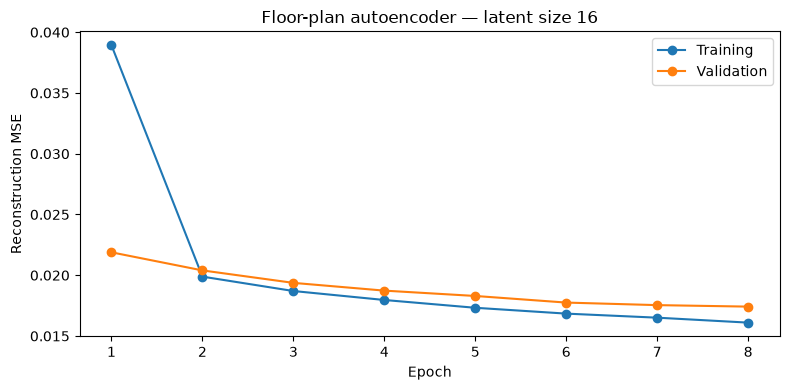

Figure saved to figures\floorplan_reconstructions_latent16.png


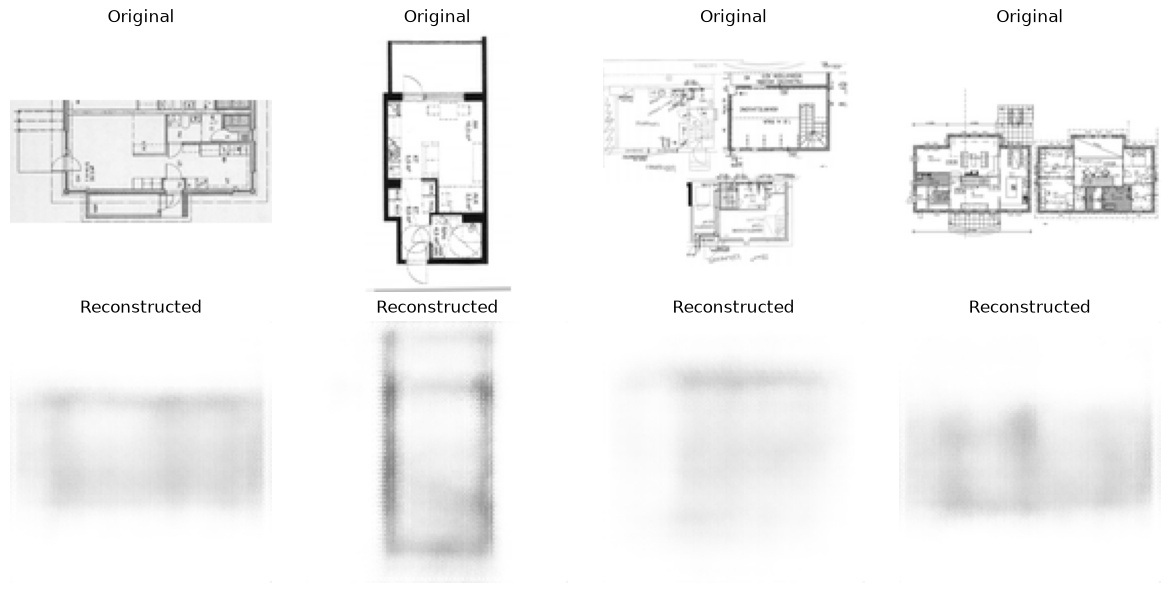

In [12]:
# Plot training and validation errors
plt.figure(figsize=(8, 4))

plt.plot(
    floorplan_history["epoch"],
    floorplan_history["train_loss"],
    marker="o",
    label="Training"
)

plt.plot(
    floorplan_history["epoch"],
    floorplan_history["val_mse"],
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Floor-plan autoencoder — latent size 16")
plt.legend()
plt.tight_layout()
save_fig("floorplan_training_latent16")
plt.show()


# Compare originals with reconstructions
examples = X_val[:4]
rebuilt = reconstruct(floorplan_ae, examples)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(
        examples[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title("Original")

    axes[1, i].imshow(
        rebuilt[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].set_title("Reconstructed")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
save_fig("floorplan_reconstructions_latent16")
plt.show()

### Initial results with latent size 16

Both training and validation reconstruction errors decreased over eight
epochs. Validation MSE fell from approximately 0.022 to 0.017.

The reconstructions retain broad visual characteristics, such as whether
a drawing is narrow and vertical or wide and horizontal. However, most
interior walls, doors and room boundaries are blurred or missing.

This suggests that the model currently captures coarse visual structure.
We cannot yet conclude that its latent codes represent meaningful
architectural layout similarity.

We will compare latent sizes 8, 16 and 32 under the same training
conditions, then inspect the retrieved floor plans.

### 3.6 Save the initial model and training history

In [13]:
MODEL_DIR.mkdir(exist_ok=True)

torch.save(
    floorplan_ae.state_dict(),
    MODEL_DIR / "floorplan_ae_latent16.pt"
)

floorplan_history.to_csv(
    "results/training_history_latent16.csv",
    index=False
)

print("Latent-16 model and history saved")

Latent-16 model and history saved


# 4. Comparing latent sizes and diagnosing failed training

We compare latent sizes 8, 16 and 32 with the same architecture family, data,
preprocessing, seed, eight-epoch budget, batch size 16 and learning rate 0.001.
The latent-16 model was trained in section 3; the next cell trains sizes 8 and 32.

The saved initial comparison reports:

| Latent size | Parameters | Training MSE | Validation MSE |
|---|---:|---:|---:|
| 8 | 156,089 | 0.0266 | 0.0284 |
| 16 | 221,633 | 0.0161 | 0.0174 |
| 32 | 352,721 | 0.0266 | 0.0284 |

The comparison table did not record the original latent-16 training duration, so
its time field remains missing rather than being invented. The model choice uses
validation results; final test evaluation is reserved for section 6.

### 4.1 Train latent sizes 8 and 32

In [14]:
models_by_latent = {16: floorplan_ae}
histories_by_latent = {16: floorplan_history}
training_seconds = {16: None}

for latent_size in [8, 32]:
    print(f"\nTraining latent size {latent_size}")

    torch.manual_seed(RANDOM_STATE)
    candidate = ConvAE128(latent_dim=latent_size)

    start = time.perf_counter()

    trained_model, history = train_autoencoder(
        candidate,
        X_train,
        X_val,
        epochs=8,
        lr=0.001,
        batch_size=16
    )

    training_seconds[latent_size] = time.perf_counter() - start
    models_by_latent[latent_size] = trained_model
    histories_by_latent[latent_size] = history

    torch.save(
        trained_model.state_dict(),
        MODEL_DIR / f"floorplan_ae_latent{latent_size}.pt"
    )

    history.to_csv(
        f"results/training_history_latent{latent_size}.csv",
        index=False
    )


Training latent size 8
epoch  1  train loss 0.0335  validation MSE 0.0284
epoch  2  train loss 0.0266  validation MSE 0.0284
epoch  3  train loss 0.0266  validation MSE 0.0284
epoch  4  train loss 0.0266  validation MSE 0.0284
epoch  5  train loss 0.0266  validation MSE 0.0284
epoch  6  train loss 0.0266  validation MSE 0.0284
epoch  7  train loss 0.0266  validation MSE 0.0284
epoch  8  train loss 0.0266  validation MSE 0.0284
trained in 43 s

Training latent size 32
epoch  1  train loss 0.0340  validation MSE 0.0284
epoch  2  train loss 0.0266  validation MSE 0.0284
epoch  3  train loss 0.0266  validation MSE 0.0284
epoch  4  train loss 0.0266  validation MSE 0.0284
epoch  5  train loss 0.0266  validation MSE 0.0284
epoch  6  train loss 0.0266  validation MSE 0.0284
epoch  7  train loss 0.0266  validation MSE 0.0284
epoch  8  train loss 0.0266  validation MSE 0.0284
trained in 48 s


### 4.2 Compare the initial runs

In [15]:
rows = []

for latent_size in [8, 16, 32]:
    trained_model = models_by_latent[latent_size]
    history = histories_by_latent[latent_size]

    rows.append({
        "latent_size": latent_size,
        "parameters": n_params(trained_model),
        "training_seconds": training_seconds[latent_size],
        "final_training_MSE": history["train_loss"].iloc[-1],
        "final_validation_MSE": reconstruction_error(
            trained_model,
            X_val,
            batch_size=32
        ).mean().item()
    })

comparison = pd.DataFrame(rows)

comparison.to_csv(
    "results/latent_size_comparison.csv",
    index=False
)

display(comparison)

,latent_size,parameters,training_seconds,final_training_MSE,final_validation_MSE
0,8,156089,42.9105,0.0266,0.0284
1,16,221633,NaN,0.0161,0.0174
2,32,352721,48.0636,0.0266,0.0284


### 4.3 Check for white output collapse

White-image baseline MSE: 0.028417
Latent 8: min=0.9952, mean=1.0000, max=1.0000, std=0.0000
Latent 16: min=0.5025, mean=0.9537, max=1.0000, std=0.0628
Latent 32: min=0.9960, mean=1.0000, max=1.0000, std=0.0000
Figure saved to figures\latent_size_reconstruction_comparison.png


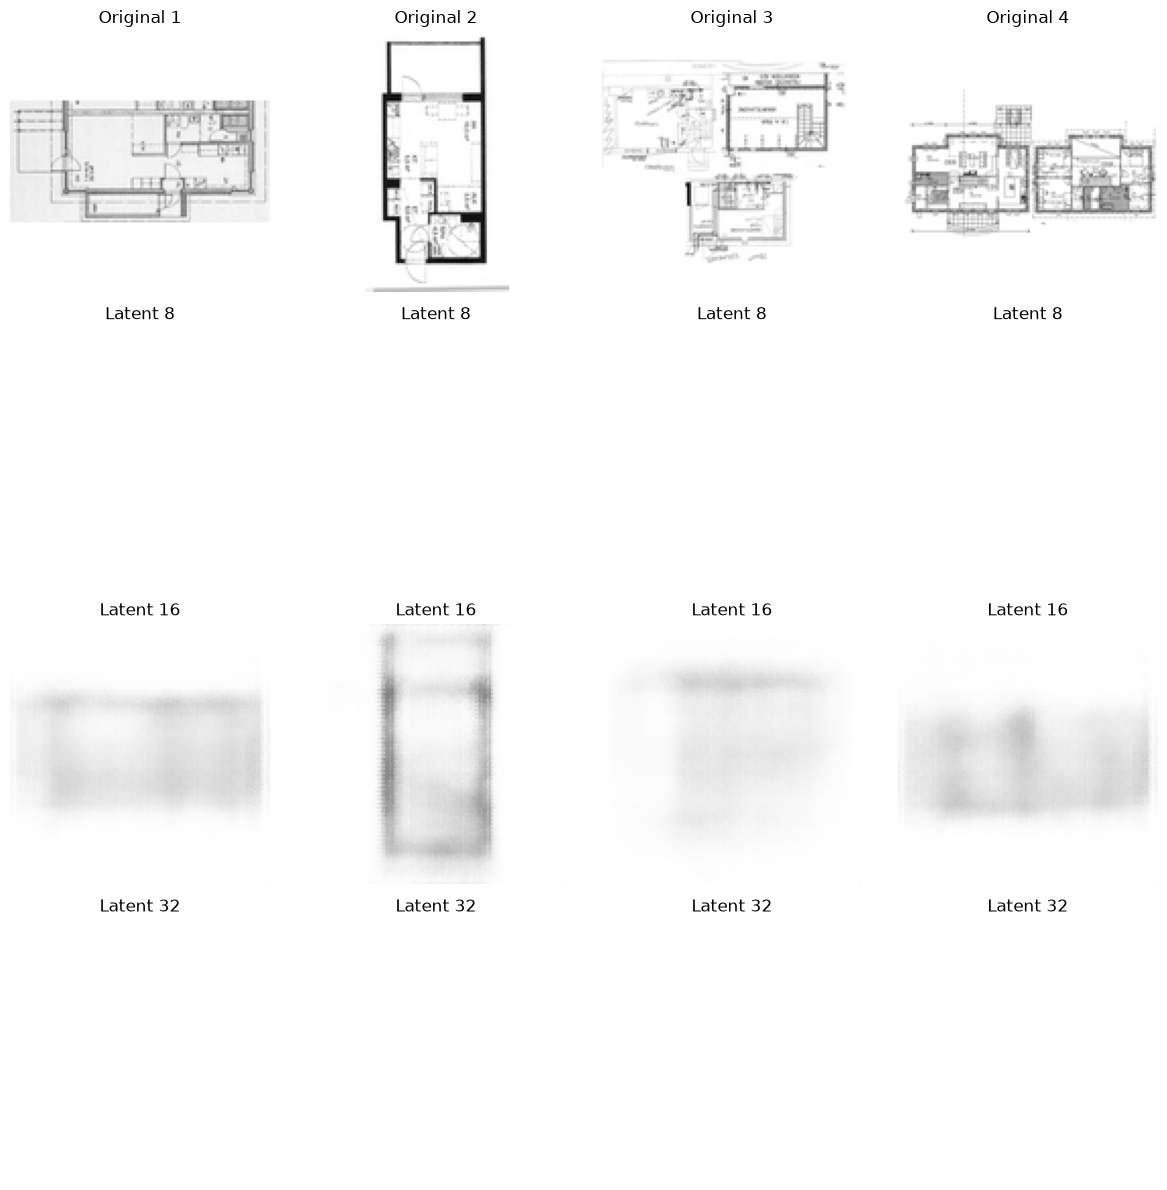

In [16]:
# Baseline: error if we output a completely white image
white_baseline_mse = ((X_val - 1.0) ** 2).mean().item()

print(f"White-image baseline MSE: {white_baseline_mse:.6f}")

# Compare the same four validation images across all models
examples = X_val[:4]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(4):
    axes[0, i].imshow(
        examples[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title(f"Original {i + 1}")

for row, latent_size in enumerate([8, 16, 32], start=1):
    rebuilt = reconstruct(
        models_by_latent[latent_size],
        examples,
        batch_size=4
    )

    print(
        f"Latent {latent_size}: "
        f"min={rebuilt.min().item():.4f}, "
        f"mean={rebuilt.mean().item():.4f}, "
        f"max={rebuilt.max().item():.4f}, "
        f"std={rebuilt.std().item():.4f}"
    )

    for i in range(4):
        axes[row, i].imshow(
            rebuilt[i, 0].numpy(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, i].set_title(f"Latent {latent_size}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
save_fig("latent_size_reconstruction_comparison")
plt.show()

The white-image validation baseline is approximately 0.028417. The initial
latent-8 and latent-32 runs have nearly the same error and output almost entirely
white images in the inspected examples. These runs failed to learn useful
reconstructions; they do not show that those latent sizes cannot work.

Latent 16 reconstructs coarse shapes, although internal walls and other small
details remain blurred. A low pixel MSE alone does not establish architectural
quality because white background pixels occupy much of each drawing.

### 4.4 Retry latent size 8 with a lower learning rate

This separate troubleshooting run reduces the learning rate from 0.001 to
0.0001 while keeping the eight-epoch budget. It is not included in the original
same-learning-rate comparison. The saved retry reached validation MSE 0.021735,
but the inspected reconstructions remained nearly uniform and weakly structured.

In [17]:
torch.manual_seed(RANDOM_STATE)

retry_ae8, retry_history8 = train_autoencoder(
    ConvAE128(latent_dim=8),
    X_train,
    X_val,
    epochs=8,
    lr=0.0001,       # Previously 0.001
    batch_size=16
)

retry_val_mse = reconstruction_error(
    retry_ae8,
    X_val,
    batch_size=32
).mean().item()

print(f"\nWhite baseline MSE: {white_baseline_mse:.6f}")
print(f"Original latent-8 MSE: {comparison.loc[comparison['latent_size'] == 8, 'final_validation_MSE'].iloc[0]:.6f}")
print(f"Retry latent-8 MSE: {retry_val_mse:.6f}")

epoch  1  train loss 0.0663  validation MSE 0.0283
epoch  2  train loss 0.0263  validation MSE 0.0278
epoch  3  train loss 0.0258  validation MSE 0.0273
epoch  4  train loss 0.0253  validation MSE 0.0263
epoch  5  train loss 0.0234  validation MSE 0.0241
epoch  6  train loss 0.0224  validation MSE 0.0236
epoch  7  train loss 0.0219  validation MSE 0.0225
epoch  8  train loss 0.0207  validation MSE 0.0217
trained in 37 s

White baseline MSE: 0.028417
Original latent-8 MSE: 0.028417
Retry latent-8 MSE: 0.021735


Output mean: 0.9519792795181274
Output standard deviation: 0.026170019060373306
Figure saved to figures\latent8_lower_learning_rate.png


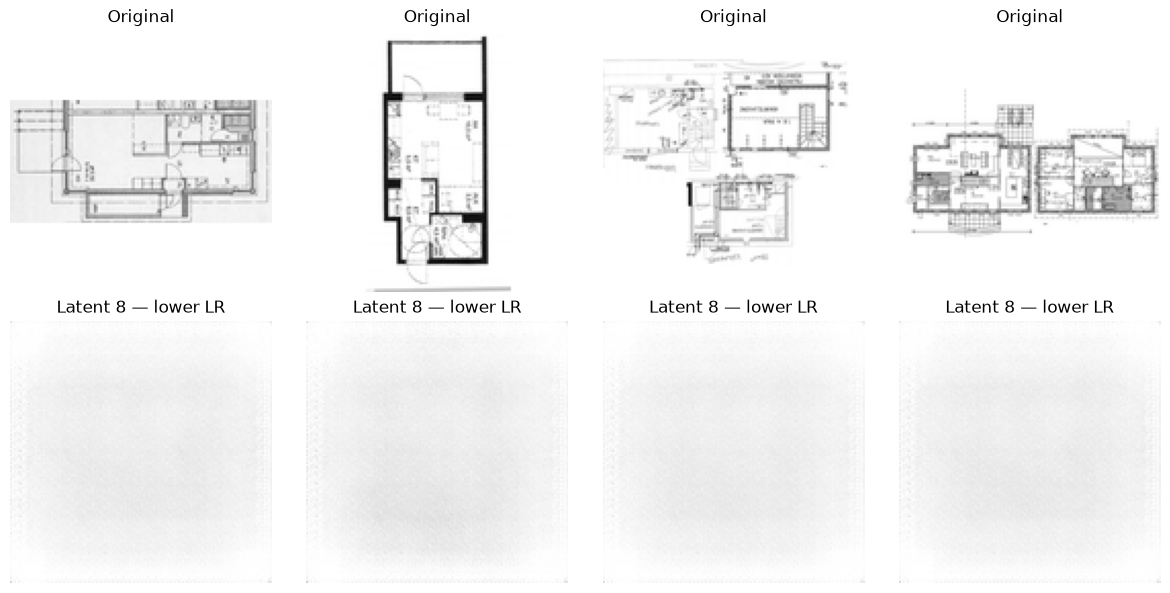

In [18]:
examples = X_val[:4]
rebuilt = reconstruct(retry_ae8, examples, batch_size=4)

print("Output mean:", rebuilt.mean().item())
print("Output standard deviation:", rebuilt.std().item())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(
        examples[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title("Original")

    axes[1, i].imshow(
        rebuilt[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].set_title("Latent 8 — lower LR")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
save_fig("latent8_lower_learning_rate")
plt.show()

### 4.5 Select a model using validation evidence

We select the original latent-16 model for the current prototype. It has the
lowest validation reconstruction error among the recorded runs and visibly
retains more input structure. This is a choice among these runs, not a general
claim that latent size 16 is optimal. Its suitability for similarity search must
also be checked using retrieved examples.

# 5. Latent space and similarity search

The training split forms the reference collection. We encode every training plan
and retain its image path in exactly the same order as its latent code.

For a query plan, we apply the same grayscale conversion, resizing, padding and
pixel scaling, encode it, and return the five reference codes with the smallest
Euclidean distances.

The queries below are validation images 10, 50 and 100. They are used for development,
not final retrieval testing. Distances are numerical differences between codes,
not confidence percentages. We inspect overall proportions, drawing composition,
internal layout differences and possible influence from margins or drawing style.

No room labels, SVG parsing or UMAP analysis are used in this experiment.

### 5.1 Encode the reference collection and validation queries

In [19]:
# Encode plans in small batches
@torch.no_grad()
def encode_plans(model, images, batch_size=32):
    model.eval()
    codes = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].to(DEVICE)
        codes.append(model.encoder(batch).cpu())

    return torch.cat(codes)


# Use the original trained latent-16 model
similarity_model = models_by_latent[16]

# Training plans form the reference collection
reference_codes = encode_plans(similarity_model, X_train)

# Use three validation plans as development queries
query_indices = [10, 50, 100]
query_images = X_val[query_indices]
query_codes = encode_plans(similarity_model, query_images)

print("Reference codes:", tuple(reference_codes.shape))
print("Query codes:", tuple(query_codes.shape))

Reference codes: (4200, 16)
Query codes: (3, 16)


### 5.2 Display five matches per query

Figure saved to figures\floorplan_similarity_latent16_more_queries.png


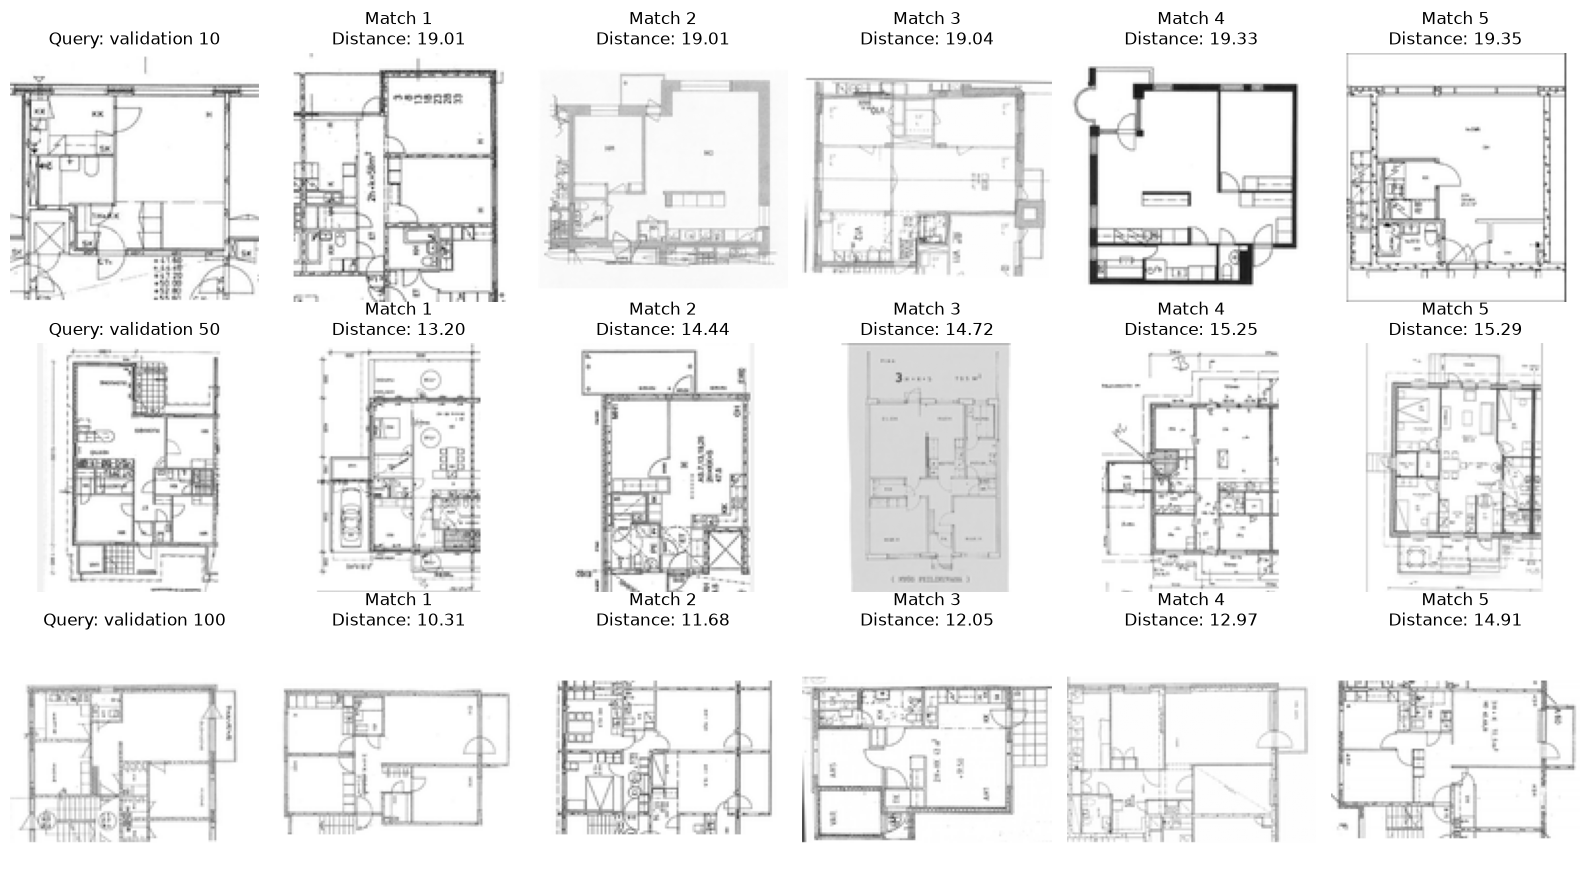

In [20]:
fig, axes = plt.subplots(3, 6, figsize=(16, 9))

for row in range(len(query_indices)):
    # Euclidean distance between this query and all reference codes
    distances = torch.linalg.vector_norm(
        reference_codes - query_codes[row],
        dim=1
    )

    nearest = torch.topk(
        distances, k=5, largest=False
    ).indices

    axes[row, 0].imshow(
        query_images[row, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[row, 0].set_title(
        f"Query: validation {query_indices[row]}"
    )

    for rank, index in enumerate(nearest.tolist(), start=1):
        axes[row, rank].imshow(
            X_train[index, 0].numpy(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, rank].set_title(
            f"Match {rank}\nDistance: {distances[index]:.2f}"
        )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
save_fig("floorplan_similarity_latent16_more_queries")
plt.show()

### 5.3 Interpret the recorded retrieval examples

The displayed validation examples retrieve drawings with broadly similar
proportions and page composition. The compact query returns several compact
plans, and the vertical query mainly returns vertically arranged drawings.
Internal room divisions still differ across the matches.

Earlier development examples also included a narrow vertical plan and a sheet
containing several separate drawings. Their matches suggested sensitivity to
outline and arrangement on the page.

These are qualitative observations, not a measured retrieval accuracy. They do
not establish understanding of room functions or circulation. Very close matches
should be checked for duplicate or related original drawings. No held-out test
retrieval demonstration is claimed.

# 6. Final reconstruction evaluation

The selected latent-16 model is evaluated on the held-out test images after the
validation-based choices. We compare it with a white-image baseline and a fixed
mean image calculated using training images only. These scores assess
reconstruction, not retrieval accuracy.

In [21]:
# Final reconstruction evaluation of the selected model
final_model = models_by_latent[16]

test_errors = reconstruction_error(
    final_model,
    X_test,
    batch_size=32
)

test_mse = test_errors.mean().item()

# Two simple reconstruction baselines
white_test_mse = ((X_test - 1.0) ** 2).mean().item()

mean_training_image = X_train.mean(dim=0, keepdim=True)
mean_image_test_mse = (
    (X_test - mean_training_image) ** 2
).mean().item()

test_results = pd.DataFrame([
    {"method": "White image baseline", "test_MSE": white_test_mse},
    {"method": "Mean training image baseline", "test_MSE": mean_image_test_mse},
    {"method": "Autoencoder latent 16", "test_MSE": test_mse}
])

display(test_results)

test_results.to_csv(
    "results/final_test_reconstruction.csv",
    index=False
)

,method,test_MSE
0,White image baseline,0.0301
1,Mean training image baseline,0.0243
2,Autoencoder latent 16,0.0185


### Final reconstruction evaluation

The selected latent-16 autoencoder achieved a test MSE of approximately
0.0185, compared with 0.0243 for the mean training image and 0.0301 for
a completely white image.

This represents approximately 24% lower reconstruction error than the
mean-image baseline.

The model therefore provides a reconstruction benefit over returning
a fixed image. However, fine architectural details remain blurred.

These scores evaluate image reconstruction, not retrieval accuracy.
Our similarity-search results are assessed qualitatively.

# 7. Saving the model and verifying ONNX

The similarity application needs the trained encoder, preprocessing settings and
a reference collection. We save:

| File | Purpose |
|---|---|
| `floorplan_ae.pt` | Full autoencoder weights |
| `floorplan_config.json` | Architecture, latent size, preprocessing and distance settings |
| `reference_codes.npy` | Training-gallery latent vectors |
| `reference_paths.json` | Image paths in the same order as the gallery vectors |
| `floorplan_encoder.onnx` | Encoder graph and weights for inference |
| `examples/*.png` | Prepared validation images for checking the app |

The app must use the same encoder version and preprocessing as the reference
codes. Image paths currently refer to the local dataset; deployment will also
need access to the corresponding reference images or thumbnails.

The saved uploaded run passed the ONNX versus PyTorch checks for batch sizes 1
and 3. The cells below reproduce the export and checks when run in your project.

### 7.1 Save weights settings and the reference collection

In [22]:
import json
import numpy as np

MODEL_APP_DIR = Path("model_app")
MODEL_APP_DIR.mkdir(exist_ok=True)

# Save the trained autoencoder weights
torch.save(
    similarity_model.state_dict(),
    MODEL_APP_DIR / "floorplan_ae.pt"
)

# Save the training-gallery codes
np.save(
    MODEL_APP_DIR / "reference_codes.npy",
    reference_codes.numpy()
)

# Preserve the same ordering as the reference codes
reference_paths = [str(path) for path in train_paths]

(MODEL_APP_DIR / "reference_paths.json").write_text(
    json.dumps(reference_paths, indent=2),
    encoding="utf-8"
)

config = {
    "architecture": "ConvAE128",
    "latent_dim": 16,
    "image_size": 128,
    "channels": 1,
    "preprocessing": {
        "grayscale": True,
        "preserve_aspect_ratio": True,
        "padding_color": 255,
        "resize_method": "LANCZOS",
        "pixel_scaling": "divide by 255"
    },
    "distance_metric": "euclidean",
    "number_of_matches": 5,
    "reference_split": "train"
}

(MODEL_APP_DIR / "floorplan_config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

assert len(reference_paths) == reference_codes.shape[0]

print("Model, reference codes, image paths and settings saved.")

Model, reference codes, image paths and settings saved.


### 7.2 Export the encoder

In [23]:
import copy
from pathlib import Path

MODEL_APP_DIR = Path("model_app")
MODEL_APP_DIR.mkdir(exist_ok=True)

# Copy the encoder so the original model stays unchanged
export_encoder = copy.deepcopy(final_model.encoder).cpu().eval()

# Two example images allow a variable batch dimension
example_input = X_val[:2].cpu()

encoder_path = MODEL_APP_DIR / "floorplan_encoder.onnx"

torch.onnx.export(
    export_encoder,
    (example_input,),
    str(encoder_path),
    input_names=["image"],
    output_names=["latent_code"],
    dynamo=True,
    dynamic_shapes=(
        {0: torch.export.Dim("batch")},
    ),
    external_data=False
)

print("Encoder exported to:", encoder_path)

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Encoder exported to: model_app\floorplan_encoder.onnx


### 7.3 Compare ONNX and PyTorch latent codes

In [24]:
import onnxruntime as ort
import numpy as np

session = ort.InferenceSession(
    str(encoder_path),
    providers=["CPUExecutionProvider"]
)

for batch_size in [1, 3]:
    batch = X_val[:batch_size].cpu()

    with torch.no_grad():
        pytorch_codes = export_encoder(batch).numpy()

    onnx_codes = session.run(
        None,
        {"image": batch.numpy()}
    )[0]

    matching = np.allclose(
        pytorch_codes,
        onnx_codes,
        rtol=1e-4,
        atol=1e-5
    )

    print(
        f"Batch {batch_size}: "
        f"output shape {onnx_codes.shape}, "
        f"matching = {matching}"
    )

    assert matching, "ONNX and PyTorch outputs differ"

print("Encoder export checks passed")


Batch 1: output shape (1, 16), matching = True
Batch 3: output shape (3, 16), matching = True
Encoder export checks passed


### 7.4 Save example inputs and check the required files

In [25]:
from pathlib import Path
from PIL import Image

MODEL_APP_DIR = Path("model_app")
EXAMPLE_DIR = MODEL_APP_DIR / "examples"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)

# Save three prepared validation images as example uploads
for index in [10, 50, 100]:
    pixels = (
        X_val[index, 0].cpu().numpy() * 255
    ).round().astype("uint8")

    Image.fromarray(pixels).save(
        EXAMPLE_DIR / f"validation_{index}.png"
    )

# Check the files needed for your similarity app
required_files = [
    "floorplan_ae.pt",
    "floorplan_encoder.onnx",
    "floorplan_config.json",
    "reference_codes.npy",
    "reference_paths.json"
]

for filename in required_files:
    path = MODEL_APP_DIR / filename
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path}")

print("\nExample images saved:", len(list(EXAMPLE_DIR.glob("*.png"))))

FOUND: model_app\floorplan_ae.pt
FOUND: model_app\floorplan_encoder.onnx
FOUND: model_app\floorplan_config.json
FOUND: model_app\reference_codes.npy
FOUND: model_app\reference_paths.json

Example images saved: 3


# 8. Day 1 deliverables

The saved notebook outputs demonstrate the following completed work:

- [x] Dataset source and split counts documented.
- [x] Grayscale 128 by 128 image preprocessing and sample preview.
- [x] Three initial latent-size setups compared under consistent settings.
- [x] White-output collapse diagnosed and a lower-learning-rate retry recorded.
- [x] Latent-16 selection explained using validation results.
- [x] Reconstruction figures and validation-query retrieval examples displayed.
- [x] Final reconstruction comparison with two baselines.
- [x] Model settings, reference codes and paths saved in the recorded local run.
- [x] ONNX encoder checks passed for batch sizes 1 and 3 in that run.
- [ ] Reorganised notebook restarted and run top to bottom in the team environment.
- [ ] Three presentation slides prepared and checked by the team.

### Three presentation slides

| Slide | Content |
|---|---|
| 1 | Dataset, preprocessing, three-setup comparison and failed-run diagnosis |
| 2 | Retrieval figure, interpretation and test reconstruction MSE 0.0185 |
| 3 | Architect uploads a floor plan and receives five visual references |

The roughly 24 percent improvement over the mean-image baseline concerns
reconstruction MSE, not similarity-search accuracy. Existing output files are
created on your own computer when the corresponding cells run; the notebook
itself does not embed the dataset or trained model files.

# 9. Conclusions and next steps

### Main findings from the saved run

- We compared convolutional autoencoders with latent sizes 8, 16 and 32.
- The initial latent-8 and latent-32 runs collapsed to nearly white outputs.
- Reducing the latent-8 learning rate improved its validation MSE, but its
  inspected reconstructions still showed little useful structure.
- We selected latent 16, with validation MSE approximately 0.0174 and test MSE
  approximately 0.0185.
- Test MSE was lower than the white-image baseline 0.0301 and mean-image baseline
  0.0243, about 24 percent lower than the latter using rounded values.
- Validation retrieval examples suggested broad similarity in proportions and
  drawing composition. Internal architectural similarity has not been validated.
- ONNX and PyTorch produced matching latent codes on the checked batches.

### Limitations

Resizing to 128 by 128 can remove thin walls, text and small details. Pixel
reconstruction error does not measure architectural quality. Drawing style,
orientation and margins can affect retrieval. Close matches need checks for
related or duplicated originals. Visual similarity does not establish equal
area, function, accessibility or regulatory compliance.

### App idea

An architect uploads a floor-plan image. The app prepares it, computes a latent
code and returns the five closest images in the reference collection, supporting
design-reference exploration with human interpretation.

### Next steps

Run the reorganised notebook in the team environment, prepare the three slides,
and connect the saved encoder and reference collection to the model service.
The reference images must be made available to the app as well as their codes.

# Appendix Possible extensions outside the current experiment

### Denoising

A future experiment could pair corrupted floor-plan inputs with clean targets.
It would need realistic corruption and checks that important details survive.
No denoising performance is claimed here.

### Anomaly detection

We have not defined or validated normal and abnormal architectural layouts.
High reconstruction error alone cannot establish that a plan is incorrect,
unsafe or non-compliant. No anomaly-detection results are claimed.

### Generative design

A separate VAE experiment could explore sampling or interpolating images.
Generated drawings would still need architectural and technical evaluation.
No generative-design results are claimed. The original clothing-demo execution
cells were removed from this project notebook.